In [2]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

from sklearn.cluster import KMeans

import warnings
warnings.filterwarnings('ignore')

import data and check for 0's

In [3]:
df = pd.read_csv('Instagram visits clustering.csv')
df.head()

,User ID,Instagram visit score,Spending_rank(0 to 100)
0,0,63,24.050708
1,1,61,25.223290
2,2,104,18.528245
3,3,82,86.890232
4,4,14,31.492397


In [4]:
df.describe()

,User ID,Instagram visit score,Spending_rank(0 to 100)
count,2600.000000,2600.000000,2600.000000
mean,1299.500000,63.323462,42.848408
std,750.699674,26.579760,28.758349
min,0.000000,5.000000,0.940709
25%,649.750000,38.000000,19.452098
50%,1299.500000,72.000000,28.013082
75%,1949.250000,86.000000,72.116945
max,2599.000000,118.000000,107.349821


In [5]:
df.isnull().sum()

User ID                    0
Instagram visit score      0
Spending_rank(0 to 100)    0
dtype: int64

2D clustering based on number of visits and time spent per visit

In [6]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit and transform your raw feature data
X = df[['Instagram visit score' , 'Spending_rank(0 to 100)']].iloc[: , :].values
X_scaled = scaler.fit_transform(X)
df_scaled = pd.DataFrame(X_scaled, columns=['Instagram visit score' , 'Spending_rank(0 to 100)'])


In [7]:
#  Pass the scaled data into KMeans
inertia = []
for n in range(1 , 11):
    algorithm = (KMeans(n_clusters = n ,init='k-means++', n_init = 10 ,max_iter=300, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
    algorithm.fit(X_scaled)
    inertia.append(algorithm.inertia_)

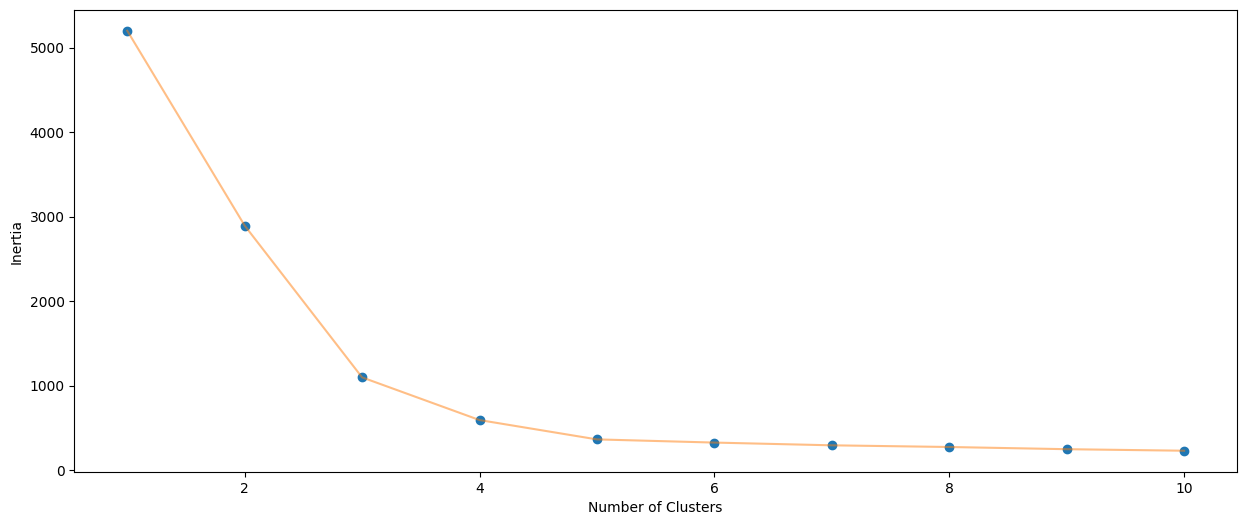

In [8]:
plt.figure(1 , figsize = (15 ,6))
plt.plot(np.arange(1 , 11) , inertia , 'o')
plt.plot(np.arange(1 , 11) , inertia , '-' , alpha = 0.5)
plt.xlabel('Number of Clusters') , plt.ylabel('Inertia')
plt.show()

elbow at 3 - use 3 clusters

In [9]:
algorithm = (KMeans(n_clusters = 3 ,init='k-means++', n_init = 10 ,max_iter=300, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
algorithm.fit(X_scaled)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_

In [10]:
h = 0.02
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z2 = algorithm.predict(np.c_[xx.ravel(), yy.ravel()]) 

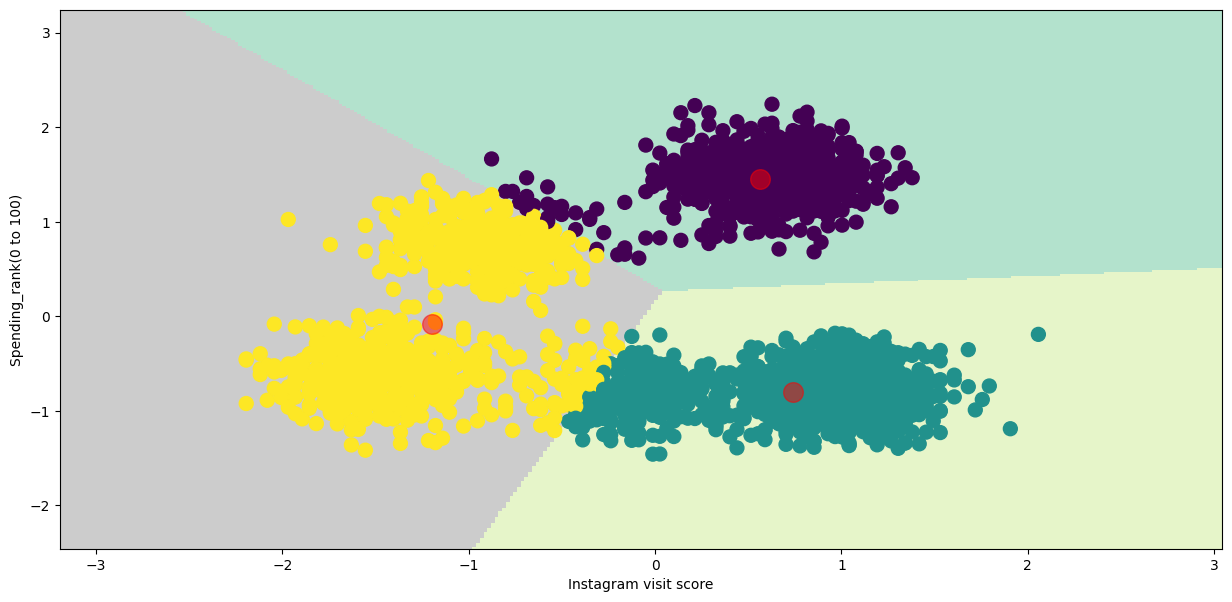

In [11]:
plt.figure(1 , figsize = (15 , 7) )
plt.clf()
Z2 = Z2.reshape(xx.shape)
plt.imshow(Z2 , interpolation='nearest', 
           extent=(xx.min(), xx.max(), yy.min(), yy.max()),
           cmap = plt.cm.Pastel2, aspect = 'auto', origin='lower')

plt.scatter( x = 'Instagram visit score' ,y = 'Spending_rank(0 to 100)' , data = df_scaled , c = labels2 , 
            s = 100 )
plt.scatter(x = centroids2[: , 0] , y =  centroids2[: , 1] , s = 200 , c = 'red' , alpha = 0.5)
plt.ylabel('Spending_rank(0 to 100)') , plt.xlabel('Instagram visit score')
plt.show()

visualized - data could be split into just 2 clusters

In [15]:
algorithm = (KMeans(n_clusters = 2 ,init='k-means++', n_init = 10 ,max_iter=300, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
algorithm.fit(X_scaled)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_

In [16]:
h = 0.02
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z2 = algorithm.predict(np.c_[xx.ravel(), yy.ravel()]) 

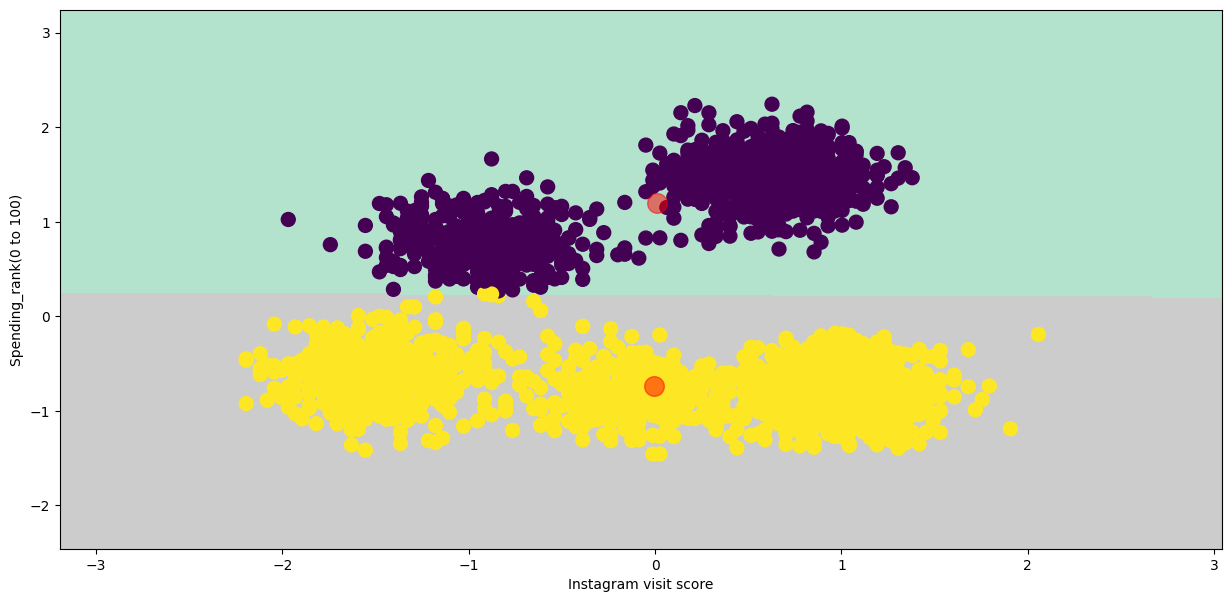

In [17]:
plt.figure(1 , figsize = (15 , 7) )
plt.clf()
Z2 = Z2.reshape(xx.shape)
plt.imshow(Z2 , interpolation='nearest', 
           extent=(xx.min(), xx.max(), yy.min(), yy.max()),
           cmap = plt.cm.Pastel2, aspect = 'auto', origin='lower')

plt.scatter( x = 'Instagram visit score' ,y = 'Spending_rank(0 to 100)' , data = df_scaled , c = labels2 , 
            s = 100 )
plt.scatter(x = centroids2[: , 0] , y =  centroids2[: , 1] , s = 200 , c = 'red' , alpha = 0.5)
plt.ylabel('Spending_rank(0 to 100)') , plt.xlabel('Instagram visit score')
plt.show()

final check - 4 clusters

In [18]:
algorithm = (KMeans(n_clusters = 4 ,init='k-means++', n_init = 10 ,max_iter=300, 
                        tol=0.0001,  random_state= 111  , algorithm='elkan') )
algorithm.fit(X_scaled)
labels2 = algorithm.labels_
centroids2 = algorithm.cluster_centers_

In [19]:
h = 0.02
x_min, x_max = X_scaled[:, 0].min() - 1, X_scaled[:, 0].max() + 1
y_min, y_max = X_scaled[:, 1].min() - 1, X_scaled[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z2 = algorithm.predict(np.c_[xx.ravel(), yy.ravel()]) 

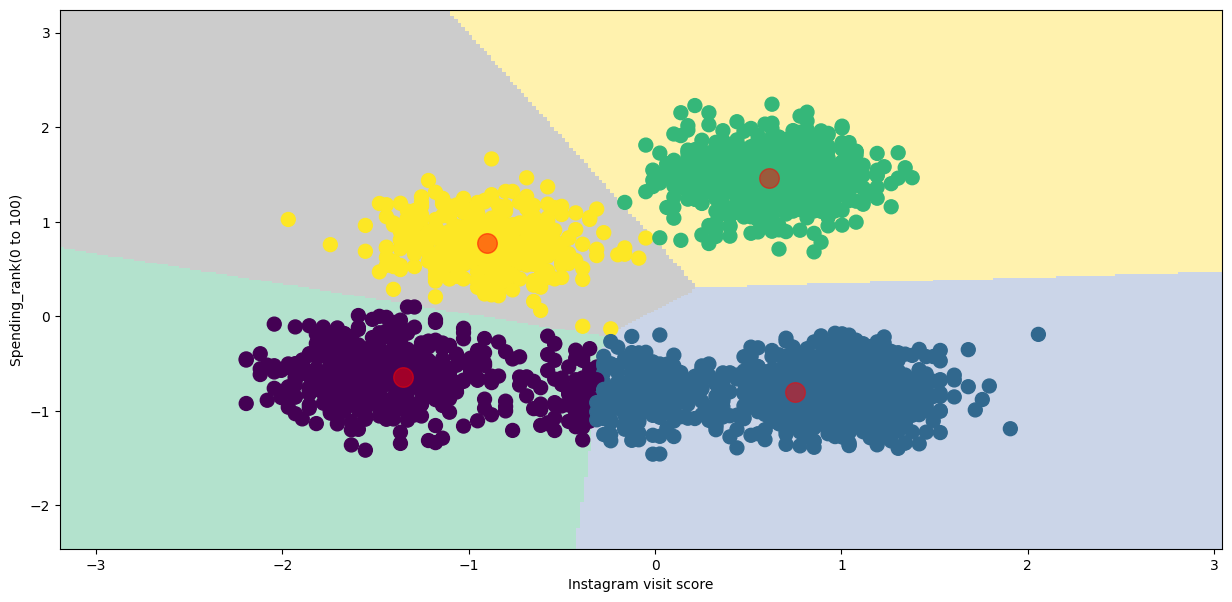

In [20]:
plt.figure(1 , figsize = (15 , 7) )
plt.clf()
Z2 = Z2.reshape(xx.shape)
plt.imshow(Z2 , interpolation='nearest', 
           extent=(xx.min(), xx.max(), yy.min(), yy.max()),
           cmap = plt.cm.Pastel2, aspect = 'auto', origin='lower')

plt.scatter( x = 'Instagram visit score' ,y = 'Spending_rank(0 to 100)' , data = df_scaled , c = labels2 , 
            s = 100 )
plt.scatter(x = centroids2[: , 0] , y =  centroids2[: , 1] , s = 200 , c = 'red' , alpha = 0.5)
plt.ylabel('Spending_rank(0 to 100)') , plt.xlabel('Instagram visit score')
plt.show()

Conculsion

The use of 3 clusters suggests the existance of 3 different groups of users. The top right cluster are users who visit the app often and for long periods of time, these may be those who could be defined as "addicted" to social media and technology. The left cluster are those who visit the app less often, there exists a group inside the cluster that spend a long amount of time on the app and a group that spend a little amout of time. The third cluster are those who open the app often, but do not spend large amounts of time on the app. This divide creates the existance of a middle group, showing mixed behavior in users. 

The use of 2 clusters suggests that those who spend less time on Instagram visit the app in a variety of times, ranging from the highest to lowest number of times. The higher spending cluster shows a tighter range of visit scores, indicating a correlation beteen high visit and high spending but not low spending and visit score. This clustering is better to create a clear divide between users.

The use of 4 clusters creates a graph-like axis where there are 4 quadrants, (high visit, high time) (high visit, low time) (low visit, high time) and (low visit, low time). The existance of each of these quadrants and a similar number of users shows variation in users. This allows users to be easily categorized by spending rank and visit score. 

In terms of addiction, the only pattern that can be concluded is the existance of the group of users who  have higher spending behavior associated with frequent visits. The clustering model does not provide proof of addiction but provides evidence of patterns of users who could be adicted. Additionally, the existance of users varying in number of visits and time spent on the app reduce the argument for an increase in addiction. 